In [50]:
''' Wine Dataset – Machine Learning Midterm

Implementation 1: Dataset Loading and Overview

In this section, the Wine dataset is loaded.  
The input features are stored in X, while the target labels are stored separately in y.'''

' Wine Dataset – Machine Learning Midterm\n\nImplementation 1: Dataset Loading and Overview\n\nIn this section, the Wine dataset is loaded.  \nThe input features are stored in X, while the target labels are stored separately in y.'

In [51]:
# Import important libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine

# Load the Wine dataset
wine_data = load_wine(as_frame=True)
df = wine_data.frame

# Separate the target variable (y) and input features (X)
y = df["target"]
X = df.drop(["target"], axis=1)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [52]:
print("Number of samples:", X.shape[0], "\nNumber of features:", X.shape[1])
print("\nTarget values:", y.unique())
print("\nTarget distribution:\n", df.groupby("target").size())
print("\nTarget names:", wine_data.target_names)

Number of samples: 178 
Number of features: 13

Target values: [0 1 2]

Target distribution:
 target
0    59
1    71
2    48
dtype: int64

Target names: ['class_0' 'class_1' 'class_2']


In [53]:
""" 2. Dataset Quality Checks

    2.1 Missing Values and Duplicates"""

' 2. Dataset Quality Checks\n\n    2.1 Missing Values and Duplicates'

In [54]:
# Checking missing values in each column
missing_values = df.isnull().sum()
print(missing_values)
"""
dup=df.duplicated().sum()
print(dup) #"sometimes data includes same data 2 times """

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


'\ndup=df.duplicated().sum()\nprint(dup) #"sometimes data includes same data 2 times '

In [55]:
print("\nTotal missing values:", missing_values.sum())

if missing_values.sum() == 0:
    print("There are no missing values in the dataset.")


Total missing values: 0
There are no missing values in the dataset.


In [56]:
""" 2.2 Potential Outliers"""

' 2.2 Potential Outliers'

In [57]:
# Calculating quartiles and IQR
q25 = X.quantile(0.25)
q75 = X.quantile(0.75)
iqr = q75 - q25
# Calculating lower and upper limits
lower_limit = q25 - 1.5 * iqr
upper_limit = q75 + 1.5 * iqr
# Detecting potential outliers
outliers = (X < lower_limit) | (X > upper_limit)
outlier_counts = outliers.sum()
print("Potential outliers in each feature:\n", outlier_counts)
print("\nTotal potential outlier values:", outlier_counts.sum())
print("Observations with at least one potential outlier:", outliers.any(axis=1).sum())

Potential outliers in each feature:
 alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                             1
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total potential outlier values: 21
Observations with at least one potential outlier: 17


In [58]:
""" 2.3 Data Types"""

' 2.3 Data Types'

In [59]:
# Checking the data type of every feature
print(X.dtypes)

numerical_features = X.select_dtypes(include=np.number)
categorical_features = X.select_dtypes(exclude=np.number)

print("\nNumber of numerical features:", numerical_features.shape[1])
print("Number of categorical features:", categorical_features.shape[1])

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

Number of numerical features: 13
Number of categorical features: 0


In [60]:
"""3. Descriptive Statistics and Visualizations

 3.1 Descriptive Statistics"""

'3. Descriptive Statistics and Visualizations\n\n 3.1 Descriptive Statistics'

In [61]:
# Calculating descriptive statistics for each feature
descriptive_statistics = pd.DataFrame({
    "Mean": X.mean(),
    "Median": X.median(),
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Standard Deviation": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75)
})

descriptive_statistics

,Mean,Median,Minimum,Maximum,Standard Deviation,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000


In [62]:
"""3.2 Class Distribution"""

'3.2 Class Distribution'

In [63]:
import seaborn as sb
import matplotlib.pyplot as plt

target
0    59
1    71
2    48
dtype: int64


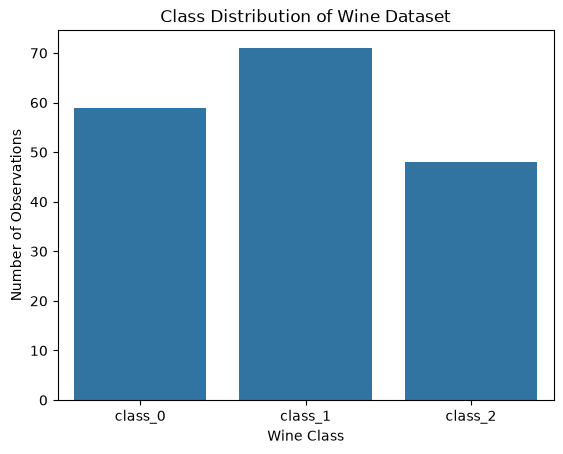

In [64]:
# Calculating the number of observations in each class
class_distribution = df.groupby("target").size()
print(class_distribution)

# Visualizing the class distribution
sb.countplot(x="target", data=df)
plt.title("Class Distribution of Wine Dataset")
plt.xlabel("Wine Class")
plt.ylabel("Number of Observations")
plt.xticks([0, 1, 2], wine_data.target_names)
plt.savefig("wine_class_distribution.png", dpi=300)
plt.show()

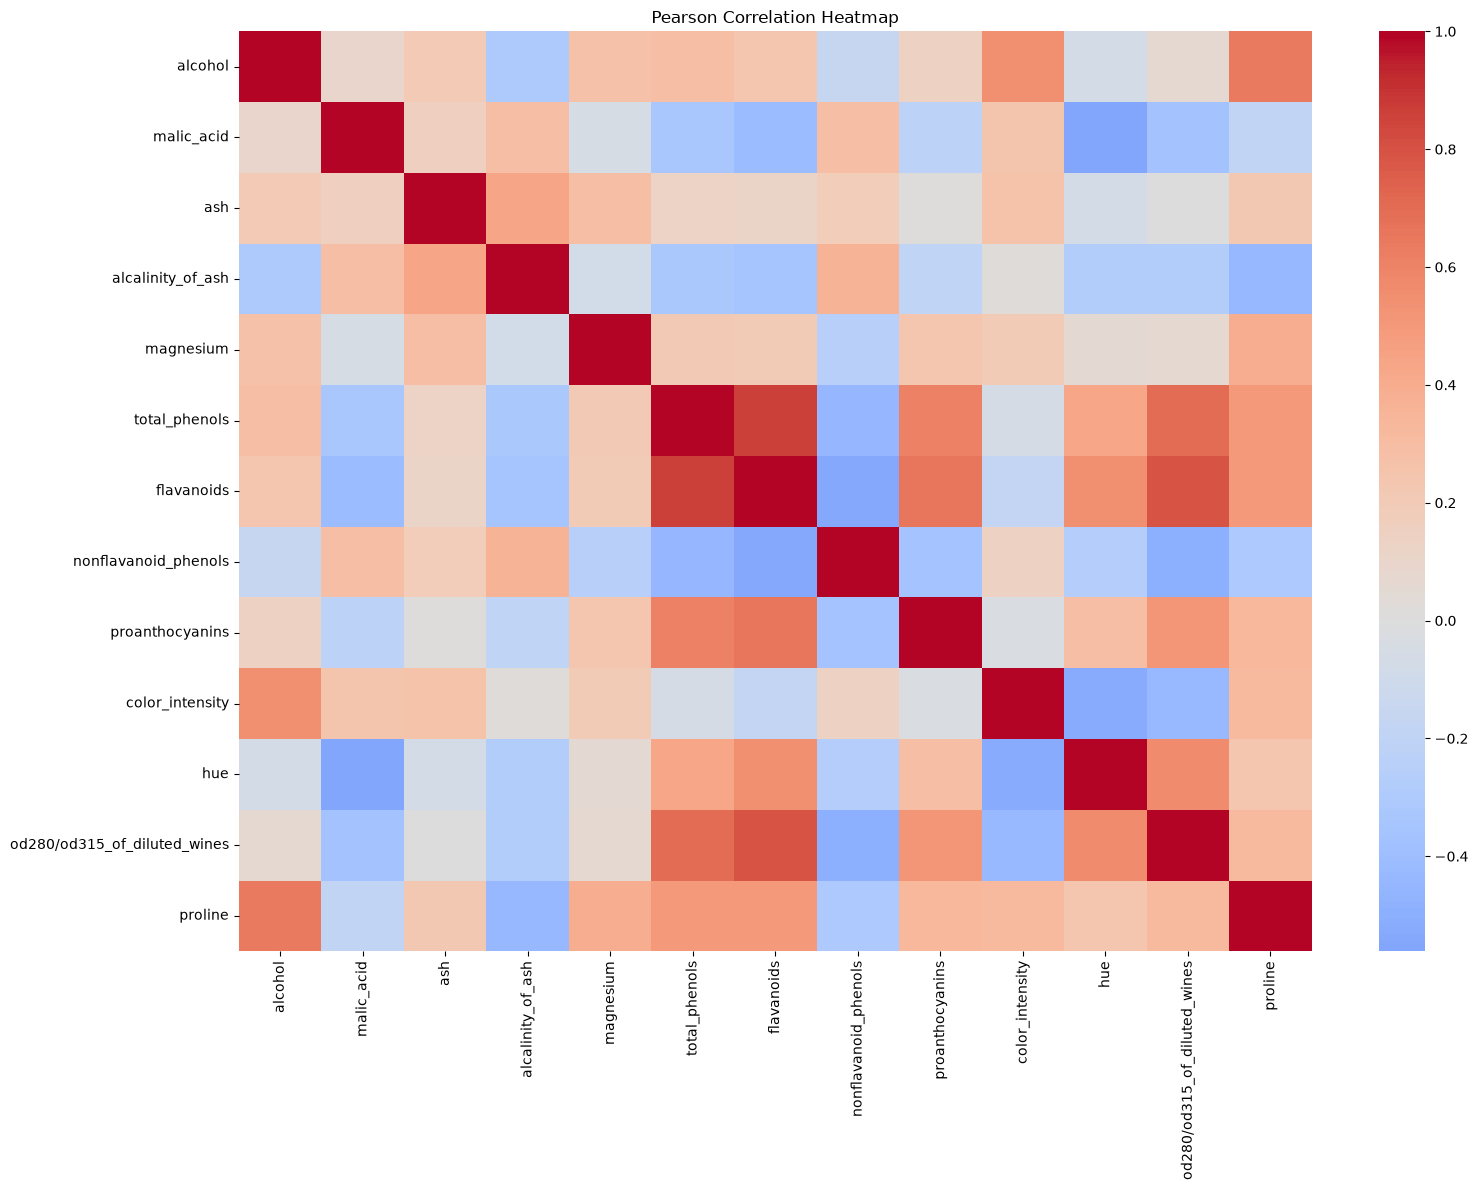

In [65]:
# Calculating the Pearson correlation matrix
correlation_matrix = X.corr(method="pearson")

# Visualizing the correlation matrix
plt.figure(figsize=(16, 12))
sb.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.savefig("wine_correlation_heatmap.png", dpi=300)
plt.show()

In [66]:
# Finding unique correlation pairs
correlation_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

# Displaying the three strongest absolute correlations
correlation_pairs.abs().nlargest(3)

total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

In [67]:
"""3.3Boxplots of All Features"""

'3.3Boxplots of All Features'

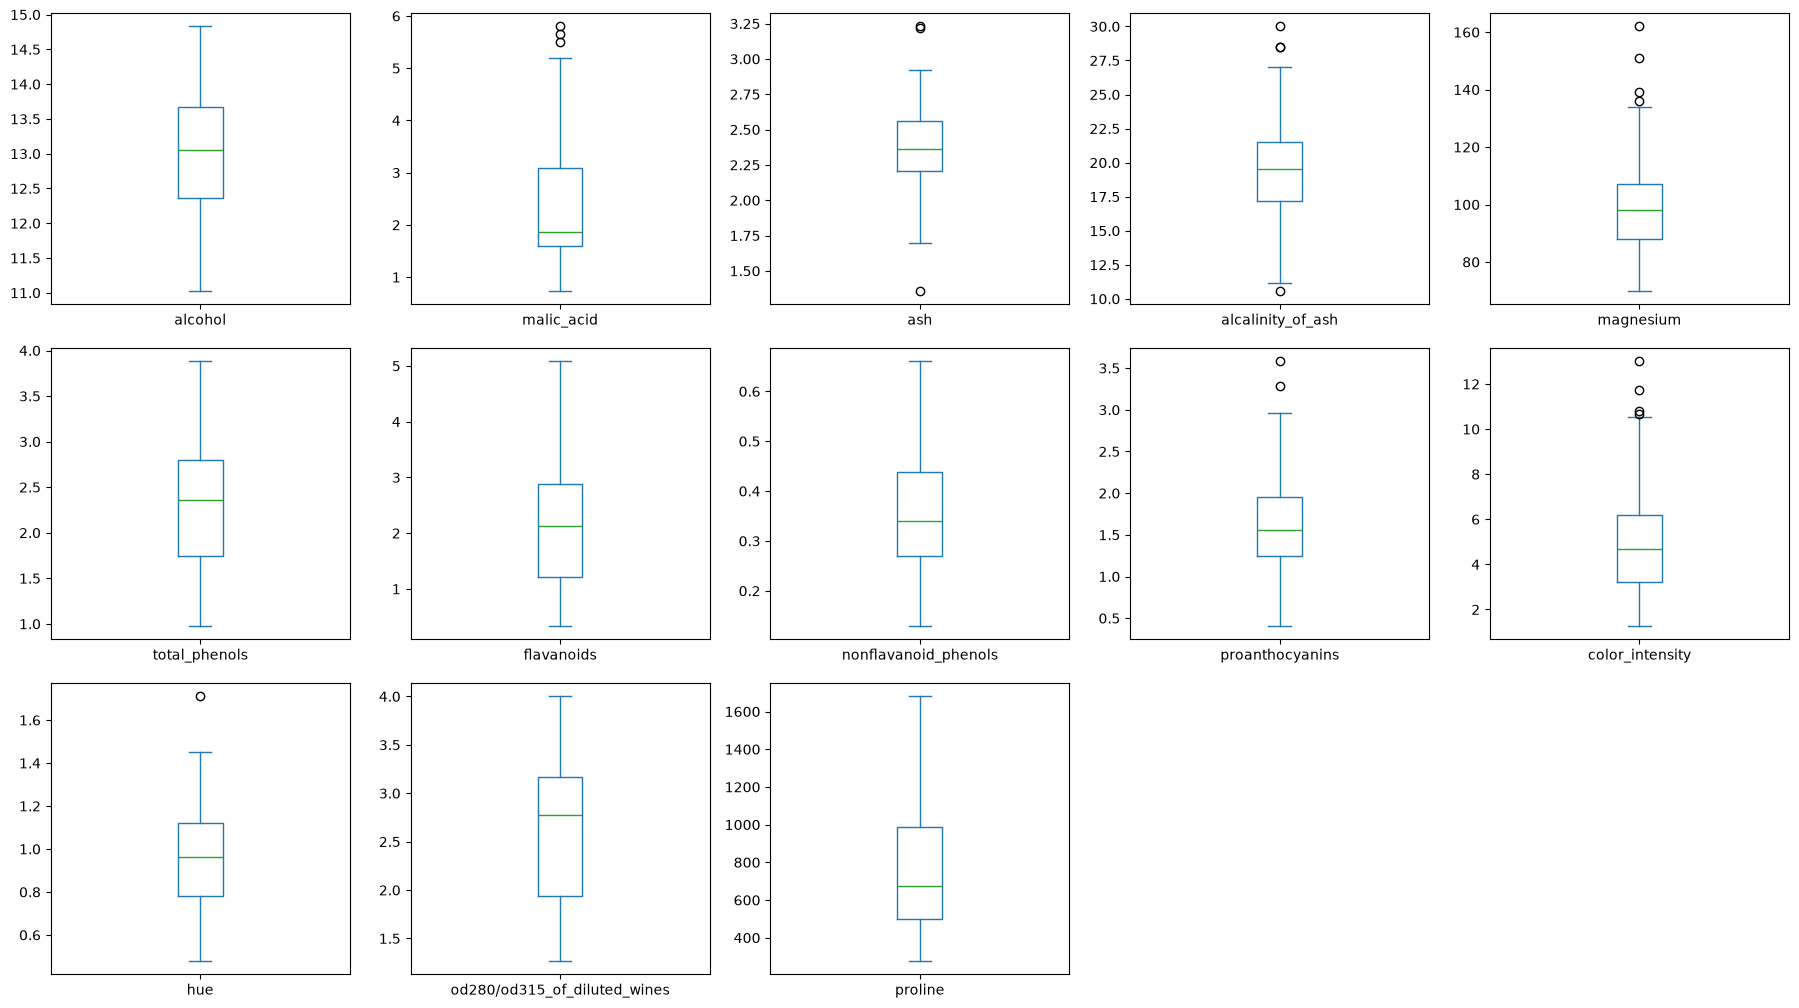

In [68]:
# Creating a separate boxplot for each feature
X.plot(
    kind="box",
    subplots=True,
    layout=(6, 5),
    figsize=(18, 20),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.savefig("wine_boxplots.png", dpi=300)
plt.show()

In [69]:
""" 4. Splitting the Datasets
    4.1 Fix the test set and repeat the training/validation split"""

' 4. Splitting the Datasets\n    4.1 Fix the test set and repeat the training/validation split'

In [70]:
from sklearn.model_selection import train_test_split
SEEDS = [42, 52, 62]
# Step 1: Reserve the 20% test set once
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
# Step 2: Split the remaining 80% into train (70%) and validation (10%) for each seed
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed)
    splits[seed] = [X_train, X_val, y_train, y_val]

In [71]:
""" 4.2 Verify the split"""

' 4.2 Verify the split'

In [72]:
# Verify the train, validation, and test splits

split_rows = []
class_rows = []

for seed in SEEDS:
    X_train, X_val, y_train, y_val = splits[seed]

    train_indices = set(X_train.index)
    val_indices = set(X_val.index)
    test_indices = set(X_test.index)

    overlap = (
        len(train_indices & val_indices)
        + len(train_indices & test_indices)
        + len(val_indices & test_indices)
    )

    total_indices = len(train_indices | val_indices | test_indices)

    print(
        "Seed:", seed,
        "- Overlap:", overlap,
        "- Total indices:", total_indices
    )

    subsets = [
        ("Train", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test)
    ]

    for subset_name, subset_X, subset_y in subsets:
        split_rows.append([
            seed,
            subset_name,
            len(subset_X),
            round(len(subset_X) / len(X) * 100, 2)
        ])

        class_counts = subset_y.value_counts().sort_index()
        class_rows.append([
            seed,
            subset_name,
            class_counts.get(0, 0),
            class_counts.get(1, 0),
            class_counts.get(2, 0)
        ])

split_table = pd.DataFrame(
    split_rows,
    columns=["Seed", "Subset", "Count", "Percentage"]
)

class_table = pd.DataFrame(
    class_rows,
    columns=["Seed", "Subset", "Class 0", "Class 1", "Class 2"]
)

print("\nSplit sizes:")
display(split_table)

print("\nClass distributions:")
display(class_table)

print("The same fixed test set is used for all seeds.")

Seed: 42 - Overlap: 0 - Total indices: 178
Seed: 52 - Overlap: 0 - Total indices: 178
Seed: 62 - Overlap: 0 - Total indices: 178

Split sizes:


,Seed,Subset,Count,Percentage
0,42,Train,124,69.66
1,42,Validation,18,10.11
2,42,Test,36,20.22
3,52,Train,124,69.66
4,52,Validation,18,10.11
5,52,Test,36,20.22
6,62,Train,124,69.66
7,62,Validation,18,10.11
8,62,Test,36,20.22



Class distributions:


,Seed,Subset,Class 0,Class 1,Class 2
0,42,Train,41,50,33
1,42,Validation,6,7,5
2,42,Test,12,14,10
3,52,Train,41,50,33
4,52,Validation,6,7,5
5,52,Test,12,14,10
6,62,Train,41,50,33
7,62,Validation,6,7,5
8,62,Test,12,14,10


The same fixed test set is used for all seeds.


In [73]:
""" 5. Data Preprocessing and Scaling
    5.1 Handle missing values"""

' 5. Data Preprocessing and Scaling\n    5.1 Handle missing values'

In [74]:
# Check missing values in the full dataset

missing_total = df.isnull().sum().sum()
print("Missing values:", missing_total)

if missing_total == 0:
    print("No missing values exist, so no imputation is applied.")

Missing values: 0
No missing values exist, so no imputation is applied.


In [75]:
""" 5.2 Select one scaler: StandardScaler"""

' 5.2 Select one scaler: StandardScaler'

In [76]:
from sklearn.preprocessing import StandardScaler

In [77]:
""" 5.3 Fit and apply the scaler correctly"""


' 5.3 Fit and apply the scaler correctly'

In [78]:
# Fit and apply a separate scaler for each seed

scalers = {}
X_train_scaled = {}
X_val_scaled = {}

for seed in SEEDS:
    X_train, X_val, y_train, y_val = splits[seed]

    scaler = StandardScaler().set_output(transform="pandas")

    X_train_scaled[seed] = scaler.fit_transform(X_train)
    X_val_scaled[seed] = scaler.transform(X_val)

    scalers[seed] = scaler

# Transform the test set using the scaler fitted under seed 42
X_test_scaled = scalers[42].transform(X_test)

# Show the first five training rows before and after scaling
print("Before scaling:")
display(splits[42][0].head())

print("After scaling:")
display(X_train_scaled[42].head())

Before scaling:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


After scaling:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


""" 6. Preparing the Two Data Representations"""

In [79]:

representations = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = splits[seed]
    representations[seed] = {
        "unscaled": {"X_train": X_train, "X_val": X_val},
        "scaled": {"X_train": X_train_scaled[seed], "X_val": X_val_scaled[seed]},
        "y_train": y_train,
        "y_val": y_val,
    }

In [80]:
# Verify the two data representations for seed 42

r = representations[42]

print("Unscaled training data:")
display(r["unscaled"]["X_train"].head())

print("Scaled training data:")
display(r["scaled"]["X_train"].head())

print("Same indices:", r["unscaled"]["X_train"].index.equals(r["scaled"]["X_train"].index))
print("Same columns:", r["unscaled"]["X_train"].columns.equals(r["scaled"]["X_train"].columns))

Unscaled training data:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Scaled training data:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


Same indices: True
Same columns: True


In [81]:
""" 7. Classifier Experiments
    7.1 Required experiments"""

' 7. Classifier Experiments\n    7.1 Required experiments'

In [82]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Train all required classifier configurations

depths = [2, 3, 5, 10, None]
neighbors = [1, 3, 5, 7, 11]
fitted = {}

for seed in SEEDS:
    for representation in ["unscaled", "scaled"]:
        X_train_rep = representations[seed][representation]["X_train"]
        y_train_rep = representations[seed]["y_train"]

        for depth in depths:
            model = DecisionTreeClassifier(
                max_depth=depth,
                random_state=seed
            )
            model.fit(X_train_rep, y_train_rep)
            fitted[(seed, representation, "dt", f"depth{depth}")] = model

        for k in neighbors:
            model = KNeighborsClassifier(
                n_neighbors=k,
                weights="uniform",
                metric="euclidean"
            )
            model.fit(X_train_rep, y_train_rep)
            fitted[(seed, representation, "knn", f"k{k}")] = model

        model = GaussianNB()
        model.fit(X_train_rep, y_train_rep)
        fitted[(seed, representation, "gnb", "default")] = model

print("Total runs:", len(fitted))

Total runs: 66


In [83]:
""" 7.2 Record and compare the experiments"""

' 7.2 Record and compare the experiments'

In [84]:
import sklearn
from sklearn.metrics import accuracy_score, f1_score

# Record the training results of all classifier runs

rows = []

for (seed, representation, algorithm, parameter), model in fitted.items():
    X_train_rep = representations[seed][representation]["X_train"]
    y_train_rep = representations[seed]["y_train"]
    train_pred = model.predict(X_train_rep)

    rows.append([
        f"wine_{algorithm}_{representation}_{parameter}_s{seed}",
        "wine", algorithm, representation, parameter, seed,
        accuracy_score(y_train_rep, train_pred),
        f1_score(y_train_rep, train_pred, average="macro")
    ])

runs = pd.DataFrame(rows, columns=[
    "Run ID", "Dataset", "Algorithm", "Representation",
    "Parameter", "Seed", "Train Acc", "Train Macro-F1"
])

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("Recorded runs:", len(runs))

scikit-learn: 1.9.1
pandas: 3.1.1
numpy: 2.5.4
Recorded runs: 66


In [85]:
""" 8. Measuring Validation Performance
    8.1 Required metrics"""

' 8. Measuring Validation Performance\n    8.1 Required metrics'

In [86]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

# Calculate validation results
validation_results = []

for run_info, model in fitted.items():
    seed, representation, algorithm, parameter = run_info

    X_val_rep = representations[seed][representation]["X_val"]
    y_val = representations[seed]["y_val"]

    y_pred = model.predict(X_val_rep)
    y_probability = model.predict_proba(X_val_rep)

    val_accuracy = accuracy_score(y_val, y_pred)
    val_precision = precision_score(y_val, y_pred, average="macro")
    val_recall = recall_score(y_val, y_pred, average="macro")
    val_f1 = f1_score(y_val, y_pred, average="macro")
    val_roc_auc = roc_auc_score(
        y_val,
        y_probability,
        multi_class="ovr",
        average="macro"
    )

    validation_results.append([
        seed,
        representation,
        algorithm,
        parameter,
        val_accuracy,
        val_precision,
        val_recall,
        val_f1,
        val_roc_auc
    ])

validation_results = pd.DataFrame(validation_results, columns=[
    "Seed",
    "Representation",
    "Algorithm",
    "Parameter",
    "Val Accuracy",
    "Val Macro-Precision",
    "Val Macro-Recall",
    "Val Macro-F1",
    "Val ROC-AUC"
])

validation_results.head()

,Seed,Representation,Algorithm,Parameter,Val Accuracy,Val Macro-Precision,Val Macro-Recall,Val Macro-F1,Val ROC-AUC
0,42,unscaled,dt,depth2,0.833333,0.863095,0.811111,0.817521,0.910596
1,42,unscaled,dt,depth3,0.944444,0.958333,0.944444,0.947475,0.968645
2,42,unscaled,dt,depth5,0.944444,0.958333,0.944444,0.947475,0.957071
3,42,unscaled,dt,depth10,0.944444,0.958333,0.944444,0.947475,0.957071
4,42,unscaled,dt,depthNone,0.944444,0.958333,0.944444,0.947475,0.957071


In [87]:
""" 8.2 Comparison tables and model selection"""

' 8.2 Comparison tables and model selection'

Selected algorithm: knn
Selected representation: scaled
Selected parameter: k11


,Run ID,Dataset,Algorithm,Representation,Parameter,Seed,Train Acc,Train Macro-F1,Val Accuracy,Val Macro-Precision,Val Macro-Recall,Val Macro-F1,Val ROC-AUC
0,wine_dt_unscaled_depth2_s42,wine,dt,unscaled,depth2,42,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,wine_dt_unscaled_depth3_s42,wine,dt,unscaled,depth3,42,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,wine_dt_unscaled_depth5_s42,wine,dt,unscaled,depth5,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,wine_dt_unscaled_depth10_s42,wine,dt,unscaled,depth10,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,wine_dt_unscaled_depthNone_s42,wine,dt,unscaled,depthNone,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine_knn_scaled_k3_s62,wine,knn,scaled,k3,62,0.959677,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000
62,wine_knn_scaled_k5_s62,wine,knn,scaled,k5,62,0.975806,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000
63,wine_knn_scaled_k7_s62,wine,knn,scaled,k7,62,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000
64,wine_knn_scaled_k11_s62,wine,knn,scaled,k11,62,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000


Train Acc         Train Macro-F1          \
                                        mean     std           mean     std   
Algorithm Representation Parameter                                            
dt        scaled         depth10      1.0000  0.0000         1.0000  0.0000   
                         depth2       0.9355  0.0081         0.9365  0.0106   
                         depth3       0.9919  0.0000         0.9926  0.0000   
                         depth5       1.0000  0.0000         1.0000  0.0000   
                         depthNone    1.0000  0.0000         1.0000  0.0000   
          unscaled       depth10      1.0000  0.0000         1.0000  0.0000   
                         depth2       0.9355  0.0081         0.9365  0.0106   
                         depth3       0.9919  0.0000         0.9926  0.0000   
                         depth5       1.0000  0.0000         1.0000  0.0000   
                         depthNone    1.0000  0.0000         1.0000  0.0000   
gnb       scaled         default      0.9839  0.0000         0.9840  0.0005   
          unscaled       default      0.9839  0.0000         0.9840  0.0005   
knn       scaled         k1           1.0000  0.0000         1.0000  0.0000   
                         k11          0.9651  0.0047         0.9656  0.0048   
                         k3           0.9677  0.0081         0.9687  0.0075   
                         k5           0.9758  0.0000         0.9762  0.0005   
                         k7           0.9597  0.0081         0.9603  0.0080   
          unscaled       k1           1.0000  0.0000         1.0000  0.0000   
                         k11          0.7392  0.0093         0.7309  0.0083   
                         k3           0.8360  0.0123         0.8294  0.0134   
                         k5           0.7876  0.0093         0.7739  0.0091   
                         k7           0.7903  0.0213         0.7804  0.0231   

                                   Val Accuracy         Val Macro-Precision  \
                                           mean     std                mean   
Algorithm Representation Parameter                                            
dt        scaled         depth10         0.9444  0.0556              0.9614   
                         depth2          0.8519  0.0321              0.8724   
                         depth3          0.9444  0.0556              0.9614   
                         depth5          0.9444  0.0556              0.9614   
                         depthNone       0.9444  0.0556              0.9614   
          unscaled       depth10         0.9444  0.0556              0.9614   
                         depth2          0.8519  0.0321              0.8724   
                         depth3          0.9444  0.0556              0.9614   
                         depth5          0.9444  0.0556              0.9614   
                         depthNone       0.9444  0.0556              0.9614   
gnb       scaled         default         0.9630  0.0321              0.9676   
          unscaled       default         0.9630  0.0321              0.9676   
knn       scaled         k1              0.9630  0.0321              0.9683   
                         k11             0.9815  0.0321              0.9815   
                         k3              0.9444  0.0556              0.9497   
                         k5              0.9815  0.0321              0.9815   
                         k7              0.9815  0.0321              0.9815   
          unscaled       k1              0.7037  0.0321              0.6886   
                         k11             0.6296  0.0321              0.6148   
                         k3              0.6667  0.0556              0.6614   
                         k5              0.7037  0.0321              0.7280   
                         k7              0.6667  0.0000              0.6471   

                                           Val Macro-Recall          \
            

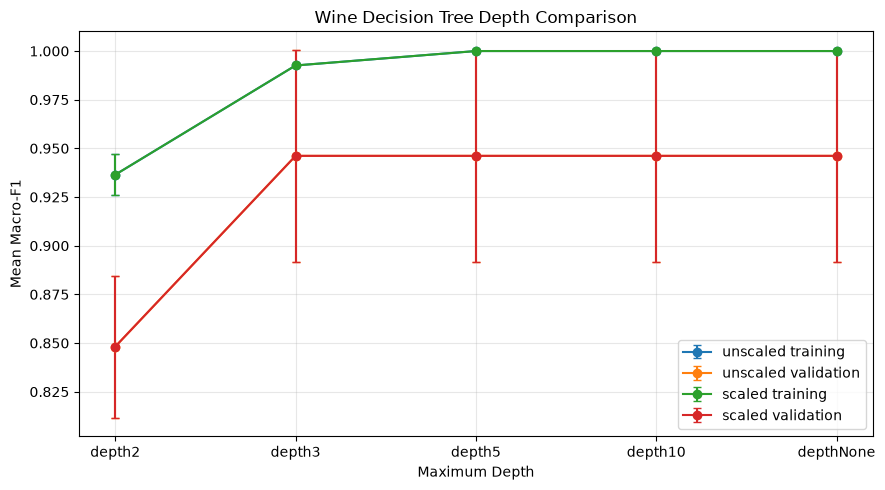

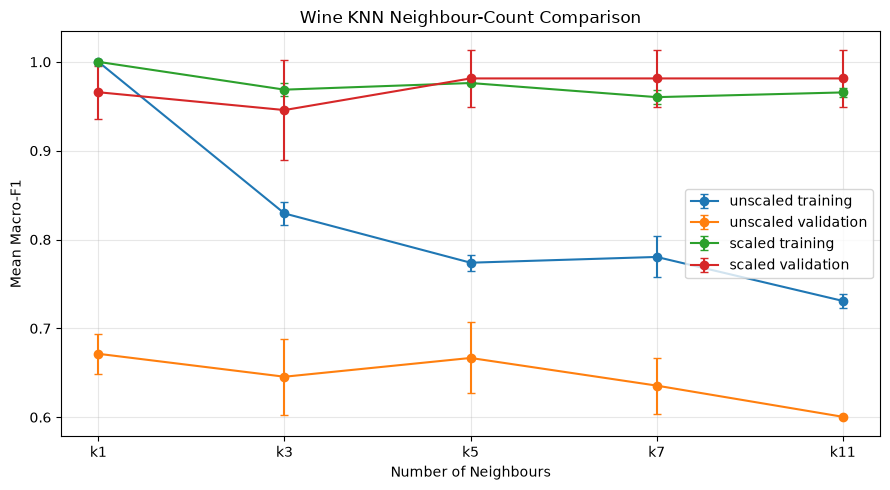

In [88]:
import matplotlib.pyplot as plt

# Combine training and validation results
run_table = pd.merge(
    runs,
    validation_results,
    on=["Seed", "Representation", "Algorithm", "Parameter"]
)

# Calculate mean and standard deviation over three seeds
metric_columns = [
    "Train Acc",
    "Train Macro-F1",
    "Val Accuracy",
    "Val Macro-Precision",
    "Val Macro-Recall",
    "Val Macro-F1",
    "Val ROC-AUC"
]

summary = run_table.groupby(
    ["Algorithm", "Representation", "Parameter"]
)[metric_columns].agg(["mean", "std"])

# Rank the configurations using validation results only
ranked = summary.sort_values(
    by=[
        ("Val Macro-F1", "mean"),
        ("Val Accuracy", "mean"),
        ("Val Macro-F1", "std")
    ],
    ascending=[False, False, True]
)

selected_algorithm = ranked.index[0][0]
selected_representation = ranked.index[0][1]
selected_parameter = ranked.index[0][2]

print("Selected algorithm:", selected_algorithm)
print("Selected representation:", selected_representation)
print("Selected parameter:", selected_parameter)

display(run_table)
display(summary.round(4))

# Required Decision Tree depth comparison figure
tree_order = ["depth2", "depth3", "depth5", "depth10", "depthNone"]
plt.figure(figsize=(9, 5))

for representation in ["unscaled", "scaled"]:
    tree_results = summary.loc[("dt", representation)].loc[tree_order]

    plt.errorbar(
        tree_order,
        tree_results["Train Macro-F1"]["mean"],
        yerr=tree_results["Train Macro-F1"]["std"],
        marker="o",
        capsize=3,
        label=representation + " training"
    )

    plt.errorbar(
        tree_order,
        tree_results["Val Macro-F1"]["mean"],
        yerr=tree_results["Val Macro-F1"]["std"],
        marker="o",
        capsize=3,
        label=representation + " validation"
    )

plt.title("Wine Decision Tree Depth Comparison")
plt.xlabel("Maximum Depth")
plt.ylabel("Mean Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("wine_tree_depth_comparison.png", dpi=300)
plt.show()

# Required KNN neighbour-count comparison figure
knn_order = ["k1", "k3", "k5", "k7", "k11"]
plt.figure(figsize=(9, 5))

for representation in ["unscaled", "scaled"]:
    knn_results = summary.loc[("knn", representation)].loc[knn_order]

    plt.errorbar(
        knn_order,
        knn_results["Train Macro-F1"]["mean"],
        yerr=knn_results["Train Macro-F1"]["std"],
        marker="o",
        capsize=3,
        label=representation + " training"
    )

    plt.errorbar(
        knn_order,
        knn_results["Val Macro-F1"]["mean"],
        yerr=knn_results["Val Macro-F1"]["std"],
        marker="o",
        capsize=3,
        label=representation + " validation"
    )

plt.title("Wine KNN Neighbour-Count Comparison")
plt.xlabel("Number of Neighbours")
plt.ylabel("Mean Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("wine_knn_neighbour_comparison.png", dpi=300)
plt.show()

In [89]:
""" 9. Evaluating the Selected Models on the Test Sets
    9.1 Final performance metrics"""
from sklearn.metrics import classification_report

# Use the model fitted with seed 42
selected_model = fitted[(
    42,
    selected_representation,
    selected_algorithm,
    selected_parameter
)]

# Select the correct test representation
if selected_representation == "scaled":
    selected_X_test = X_test_scaled
else:
    selected_X_test = X_test

# Make the final test predictions
y_test_pred = selected_model.predict(selected_X_test)
y_test_probability = selected_model.predict_proba(selected_X_test)

# Calculate final test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average="macro")
test_recall = recall_score(y_test, y_test_pred, average="macro")
test_f1 = f1_score(y_test, y_test_pred, average="macro")
test_roc_auc = roc_auc_score(
    y_test,
    y_test_probability,
    multi_class="ovr",
    average="macro"
)

# Store the final results
final = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Test Macro-Precision",
        "Test Macro-Recall",
        "Test Macro-F1",
        "Test ROC-AUC"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc
    ]
})

display(final.round(4))

print(classification_report(
    y_test,
    y_test_pred,
    target_names=wine_data.target_names
))

,Metric,Value
0,Test Accuracy,1.0
1,Test Macro-Precision,1.0
2,Test Macro-Recall,1.0
3,Test Macro-F1,1.0
4,Test ROC-AUC,1.0


              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



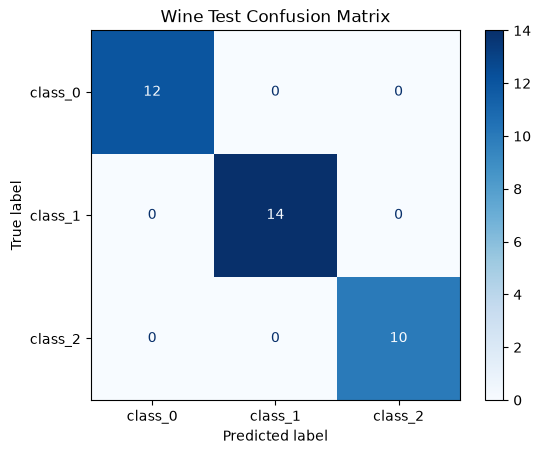

,Class,Precision,Recall,F1-score,Support
0,class_0,1.0,1.0,1.0,12
1,class_1,1.0,1.0,1.0,14
2,class_2,1.0,1.0,1.0,10


In [90]:
""" 9.2 Confusion matrices"""
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_fscore_support

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

# Display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine_data.target_names
)

display_matrix.plot(cmap="Blues")
plt.title("Wine Test Confusion Matrix")
plt.savefig("wine_confusion_matrix.png", dpi=300)
plt.show()

# Calculate precision, recall, and F1-score for every class
class_precision, class_recall, class_f1, class_support = (
    precision_recall_fscore_support(
        y_test,
        y_test_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

class_metrics = pd.DataFrame({
    "Class": wine_data.target_names,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1-score": class_f1,
    "Support": class_support
})

display(class_metrics.round(4))

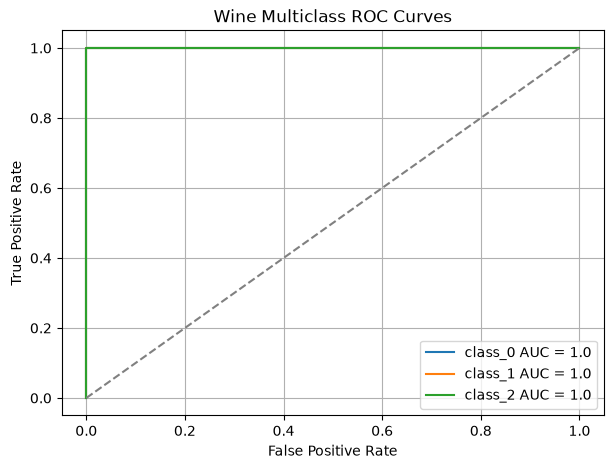

In [91]:
""" 9.3 ROC curves"""
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.preprocessing import label_binarize

# Convert the three classes into one-vs-rest binary columns
y_test_binary = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

# Draw one ROC curve for every wine class
for class_number in range(3):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_test_binary[:, class_number],
        y_test_probability[:, class_number]
    )

    class_auc = auc(
        false_positive_rate,
        true_positive_rate
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            wine_data.target_names[class_number]
            + " AUC = "
            + str(round(class_auc, 4))
        )
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Wine Multiclass ROC Curves")
plt.legend()
plt.grid()
plt.savefig("wine_roc_curves.png", dpi=300)
plt.show()

In [92]:
""" 9.4 Error interpretation"""
# Find incorrectly classified observations
error_mask = y_test != y_test_pred
error_indices = y_test[error_mask].index

error_results = pd.DataFrame({
    "Actual Class": y_test.loc[error_indices],
    "Predicted Class": y_test_pred[error_mask],
    "Prediction Probability": y_test_probability[error_mask].max(axis=1)
})

print("Number of classification errors:", len(error_results))
display(error_results.round(4))

Number of classification errors: 0


,Actual Class,Predicted Class,Prediction Probability


In [93]:
""" 10. K-Means Clustering
    10.1 Fit the clustering model"""
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score

kmeans_models = {}
kmeans_results = []

# Train K-Means for every seed and representation
for seed in SEEDS:
    for representation in ["unscaled", "scaled"]:

        X_train_rep = representations[seed][representation]["X_train"]
        X_val_rep = representations[seed][representation]["X_val"]
        y_val = representations[seed]["y_val"]

        # Fit K-Means on training data only
        kmeans_model = KMeans(
            n_clusters=3,
            random_state=seed,
            n_init=10
        )

        kmeans_model.fit(X_train_rep)

        # Store the fitted model
        kmeans_models[(seed, representation)] = kmeans_model

        # Predict validation clusters
        val_clusters = kmeans_model.predict(X_val_rep)

        # Calculate validation metrics
        val_ari = adjusted_rand_score(
            y_val,
            val_clusters
        )

        val_silhouette = silhouette_score(
            X_val_rep,
            val_clusters
        )

        kmeans_results.append([
            seed,
            representation,
            kmeans_model.inertia_,
            val_ari,
            val_silhouette
        ])

# Create the K-Means result table
kmeans_runs = pd.DataFrame(
    kmeans_results,
    columns=[
        "Seed",
        "Representation",
        "Train Inertia",
        "Val ARI",
        "Val Silhouette"
    ]
)

display(kmeans_runs.round(4))
# Summarise the K-Means validation results
kmeans_summary = kmeans_runs.groupby(
    "Representation"
)[
    ["Train Inertia", "Val ARI", "Val Silhouette"]
].agg(["mean", "std"])

display(kmeans_summary.round(4))

,Seed,Representation,Train Inertia,Val ARI,Val Silhouette
0,42,unscaled,1.350496e+06,0.2828,0.4870
1,42,scaled,8.747391e+02,1.0000,0.2516
2,52,unscaled,1.303675e+06,0.4006,0.5559
3,52,scaled,8.904355e+02,1.0000,0.3010
4,62,unscaled,1.390754e+06,0.4006,0.6867
5,62,scaled,8.722466e+02,1.0000,0.2726


Train Inertia             Val ARI        Val Silhouette        
                        mean         std    mean    std           mean     std
Representation                                                                
scaled          8.791404e+02      9.8609  1.0000  0.000         0.2751  0.0248
unscaled        1.348308e+06  43580.9098  0.3613  0.068         0.5765  0.1014

In [94]:
# Verify that the two test representations contain the same rows
print("Same test indices:", X_test.index.equals(X_test_scaled.index))
print("Test samples:", len(X_test))

Same test indices: True
Test samples: 36


In [95]:
""" 10.2 Final cluster evaluation on the fixed test set"""
# Evaluate the seed 42 K-Means models on the fixed test set
kmeans_test_results = []

for representation in ["unscaled", "scaled"]:

    # Select the correct test representation
    if representation == "scaled":
        X_test_rep = X_test_scaled
    else:
        X_test_rep = X_test

    # Use the model fitted with seed 42
    kmeans_model = kmeans_models[(42, representation)]

    # Predict test clusters
    test_clusters = kmeans_model.predict(X_test_rep)

    # Calculate test metrics
    test_ari = adjusted_rand_score(
        y_test,
        test_clusters
    )

    test_silhouette = silhouette_score(
        X_test_rep,
        test_clusters
    )

    kmeans_test_results.append([
        representation,
        test_ari,
        test_silhouette
    ])

    # Compare actual classes and predicted clusters
    comparison_table = pd.crosstab(
        y_test,
        test_clusters,
        rownames=["Actual Class"],
        colnames=["Cluster"],
        margins=True
    )

    print("\nRepresentation:", representation)
    display(comparison_table)

# Create the final K-Means test table
kmeans_test = pd.DataFrame(
    kmeans_test_results,
    columns=[
        "Representation",
        "Test ARI",
        "Test Silhouette"
    ]
)

display(kmeans_test.round(4))


Representation: unscaled


Cluster,0,1,2,All
Actual Class,,,,
0,2,10,0,12
1,5,0,9,14
2,7,0,3,10
All,14,10,12,36



Representation: scaled


Cluster,0,1,2,All
Actual Class,,,,
0,12,0,0,12
1,1,13,0,14
2,0,0,10,10
All,13,13,10,36


,Representation,Test ARI,Test Silhouette
0,unscaled,0.3733,0.4929
1,scaled,0.9088,0.2711


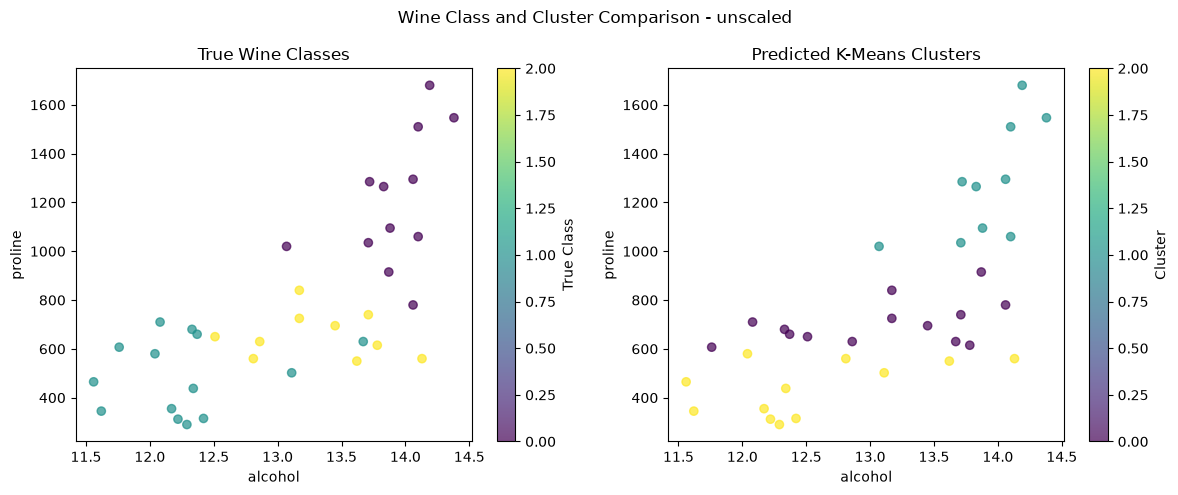

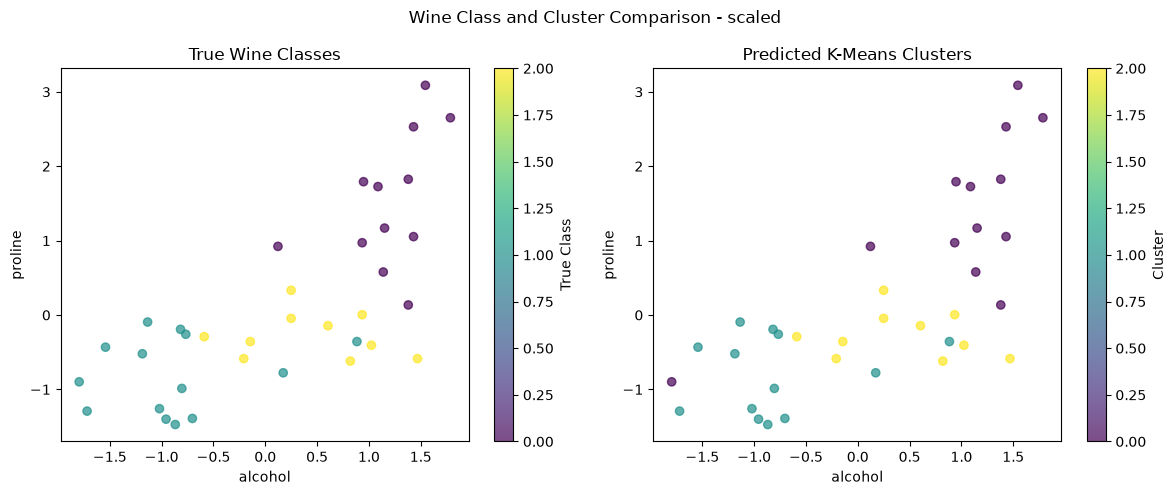

In [96]:
""" 10.3 Visualise and interpret the clusters"""
# Features used only for two-dimensional visualisation
x_feature = "alcohol"
y_feature = "proline"

for representation in ["unscaled", "scaled"]:

    # Select the correct test representation
    if representation == "scaled":
        X_test_rep = X_test_scaled
    else:
        X_test_rep = X_test

    # Get the corresponding K-Means model
    kmeans_model = kmeans_models[(42, representation)]

    # Predict test clusters
    test_clusters = kmeans_model.predict(X_test_rep)

    # Create the required two-panel figure
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))

    true_plot = axes[0].scatter(
        X_test_rep[x_feature],
        X_test_rep[y_feature],
        c=y_test,
        cmap="viridis",
        alpha=0.7
    )

    axes[0].set_xlabel(x_feature)
    axes[0].set_ylabel(y_feature)
    axes[0].set_title("True Wine Classes")
    figure.colorbar(true_plot, ax=axes[0], label="True Class")

    cluster_plot = axes[1].scatter(
        X_test_rep[x_feature],
        X_test_rep[y_feature],
        c=test_clusters,
        cmap="viridis",
        alpha=0.7
    )

    axes[1].set_xlabel(x_feature)
    axes[1].set_ylabel(y_feature)
    axes[1].set_title("Predicted K-Means Clusters")
    figure.colorbar(cluster_plot, ax=axes[1], label="Cluster")

    figure.suptitle(
        "Wine Class and Cluster Comparison - " + representation
    )
    plt.tight_layout()
    plt.savefig(
        "wine_kmeans_" + representation + "_comparison.png",
        dpi=300
    )
    plt.show()

In [97]:
""" 12. Required Run and Output Inventory
    12.1 Count the runs correctly"""
# Count classifier and K-Means model fits
classifier_fit_count = len(fitted)
kmeans_fit_count = len(kmeans_models)

total_fit_count = (
    classifier_fit_count + kmeans_fit_count
)

print("Classifier fits:", classifier_fit_count)
print("K-Means fits:", kmeans_fit_count)
print("Total fits:", total_fit_count)

Classifier fits: 66
K-Means fits: 6
Total fits: 72


In [98]:
""" 12.2 Export six result files"""

# 1. Classifier run results
classifier_runs = run_table.copy()

# 2. Classifier summary results
classifier_summary = summary.copy()
classifier_summary.columns = [
    column[0] + " " + column[1]
    for column in classifier_summary.columns
]
classifier_summary = classifier_summary.reset_index()
classifier_summary.insert(0, "Dataset", "wine")

# 3. Final classifier test result
classifier_test = final.set_index("Metric").T
classifier_test.insert(0, "Seed", 42)
classifier_test.insert(
    0,
    "Selected Configuration",
    selected_algorithm
    + "_"
    + selected_representation
    + "_"
    + selected_parameter
)
classifier_test.insert(0, "Dataset", "wine")

# 4. K-Means run results
kmeans_runs_export = kmeans_runs.copy()
kmeans_runs_export.insert(0, "Dataset", "wine")

# 5. K-Means summary results
kmeans_summary_export = kmeans_summary.copy()
kmeans_summary_export.columns = [
    column[0] + " " + column[1]
    for column in kmeans_summary_export.columns
]
kmeans_summary_export = kmeans_summary_export.reset_index()
kmeans_summary_export.insert(0, "Dataset", "wine")

# 6. Final K-Means test results
kmeans_test_export = kmeans_test.copy()
kmeans_test_export.insert(0, "Seed", 42)
kmeans_test_export.insert(0, "Dataset", "wine")

# Save the six result files
result_files = {
    "classifier_runs.csv": classifier_runs,
    "classifier_summary.csv": classifier_summary,
    "classifier_test.csv": classifier_test,
    "kmeans_runs.csv": kmeans_runs_export,
    "kmeans_summary.csv": kmeans_summary_export,
    "kmeans_test.csv": kmeans_test_export
}

for file_name, result_table in result_files.items():
    result_table.to_csv(file_name, index=False)

    print(
        file_name,
        "-",
        len(result_table),
        "rows"
    )

classifier_runs.csv - 66 rows
classifier_summary.csv - 22 rows
classifier_test.csv - 1 rows
kmeans_runs.csv - 6 rows
kmeans_summary.csv - 2 rows
kmeans_test.csv - 2 rows
